In [1]:
!conda list | grep statsmodels

statsmodels               0.13.5                   pypi_0    pypi


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import scipy.integrate as integrate
from ipywidgets import interact

from statsmodels.distributions.copula.api import (
    CopulaDistribution, IndependenceCopula, GaussianCopula, StudentTCopula)

!date
!whoami
!uname -a
!python --version
!pwd

Mon Aug 21 23:17:38 PDT 2023
ndbs
Darwin ndbs-Q9Q94K6GHF 22.6.0 Darwin Kernel Version 22.6.0: Wed Jul  5 22:22:05 PDT 2023; root:xnu-8796.141.3~6/RELEASE_ARM64_T6000 arm64
Python 3.9.13
/Users/ndbs/repos/vivarium_data_analysis/probability


In [9]:
sns.set_style("darkgrid")
sns.mpl.rc("figure", figsize=(8, 8))

# Gaussian copulae with correlations 0.1, 0.5, and 0.9

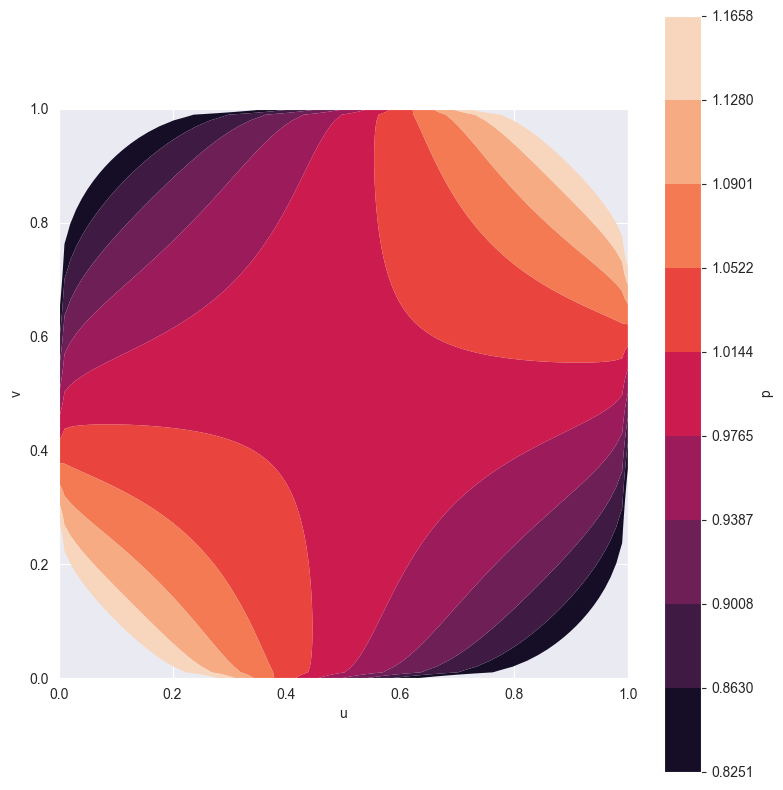

In [17]:
copula = GaussianCopula(0.1, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

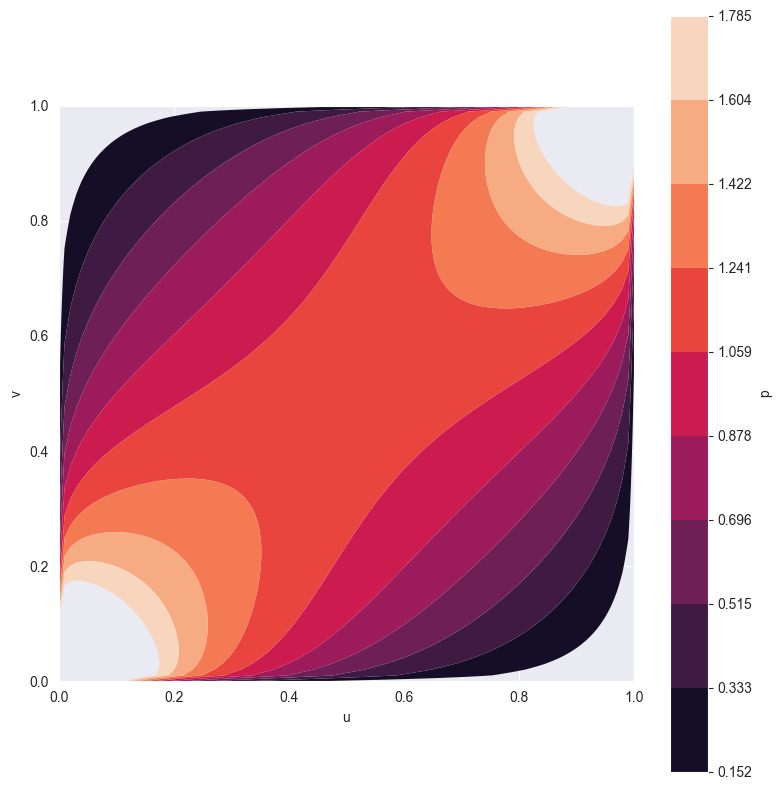

In [11]:
copula = GaussianCopula(0.5, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

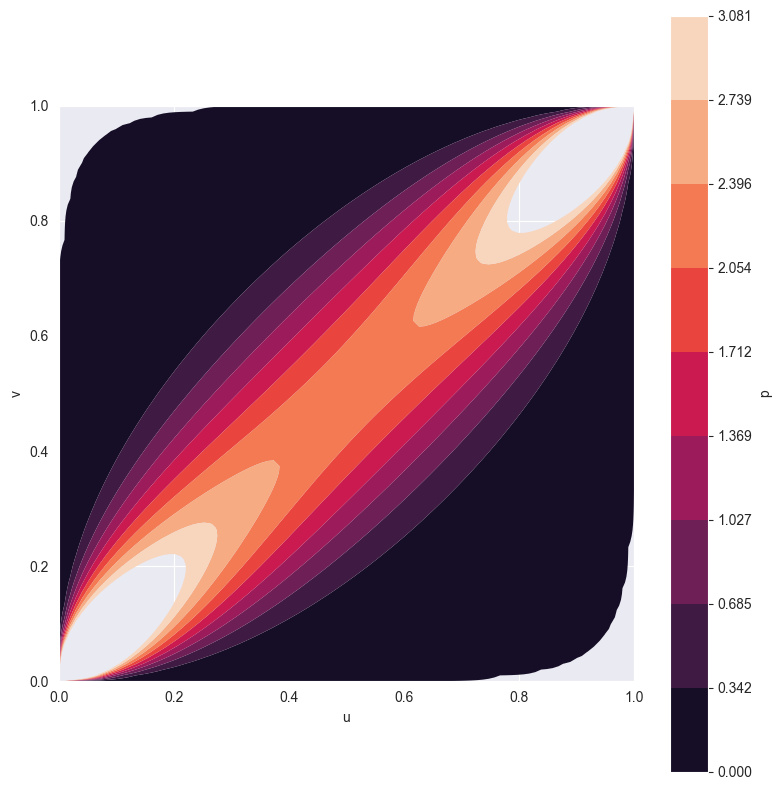

In [48]:
copula = GaussianCopula(0.9, k_dim=2)
fig = copula.plot_pdf()  # returns a matplotlib figure

In [51]:
fig.get_axes()

[<AxesSubplot: xlabel='u', ylabel='v'>,
 <AxesSubplot: label='<colorbar>', ylabel='p'>]

# Function to plot Gaussian copulae with varying correlation coefficient

In [57]:

@interact(rho=(-1.0,1.0))
def plot_gaussian_copula_from_correlation(rho):
    if rho==0:
        print("constant pdf")
    elif rho==1 or rho==-1:
        print("degenerate pdf")
    else:
        copula = GaussianCopula(rho, k_dim=2)
        _ = copula.plot_pdf()  # returns a matplotlib figure

interactive(children=(FloatSlider(value=0.0, description='rho', max=1.0, min=-1.0), Output()), _dom_classes=('…

# Some Gaussian copulae with some arbitary made up correlation (covariance?) matrices

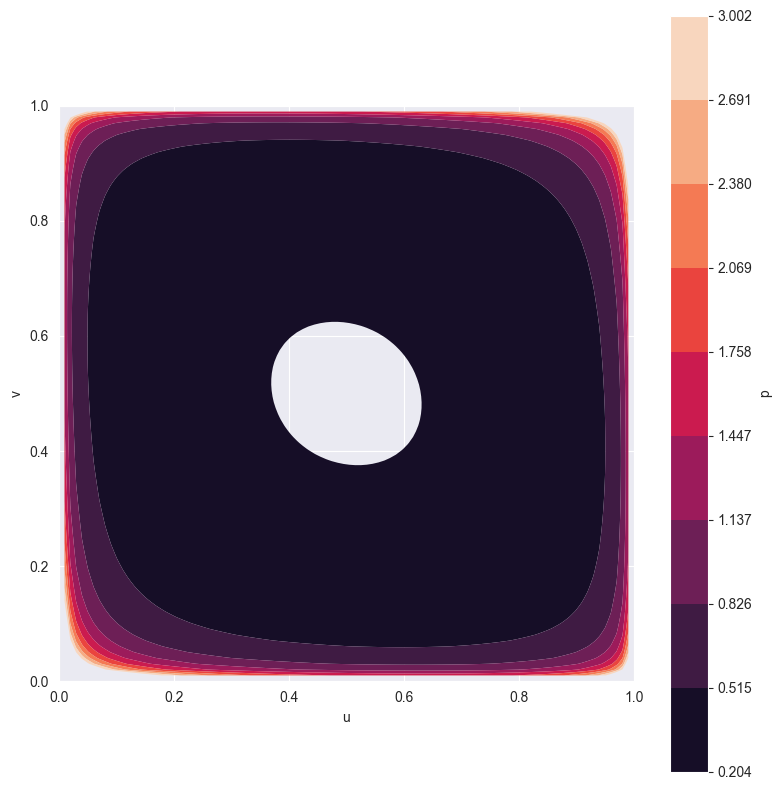

In [18]:
copula = GaussianCopula([[5,3],[3,7]], k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

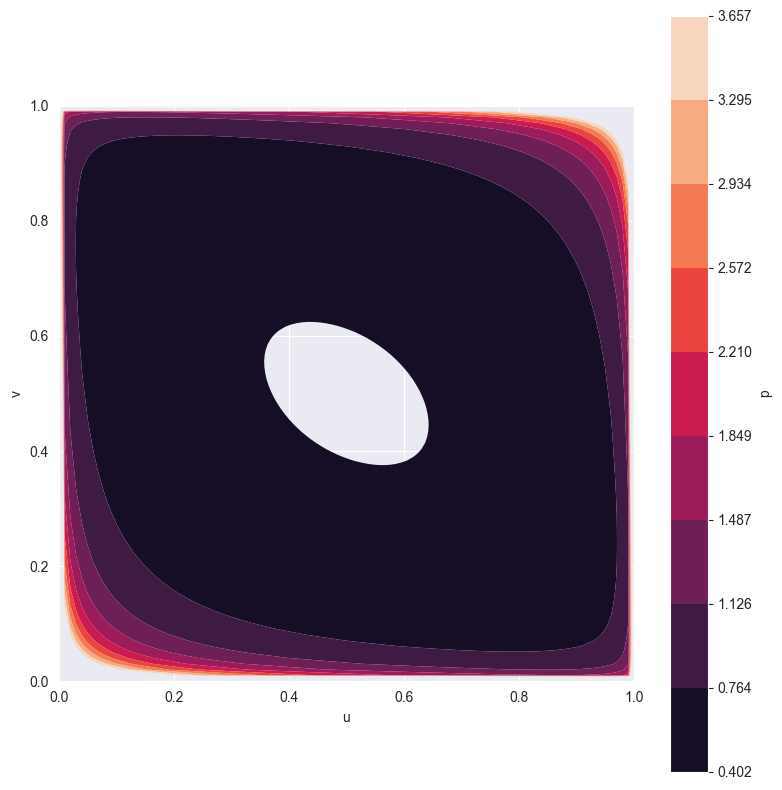

In [79]:
copula = GaussianCopula([[0.5*5,0.5*3],[0.5*3,0.5*7]], k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

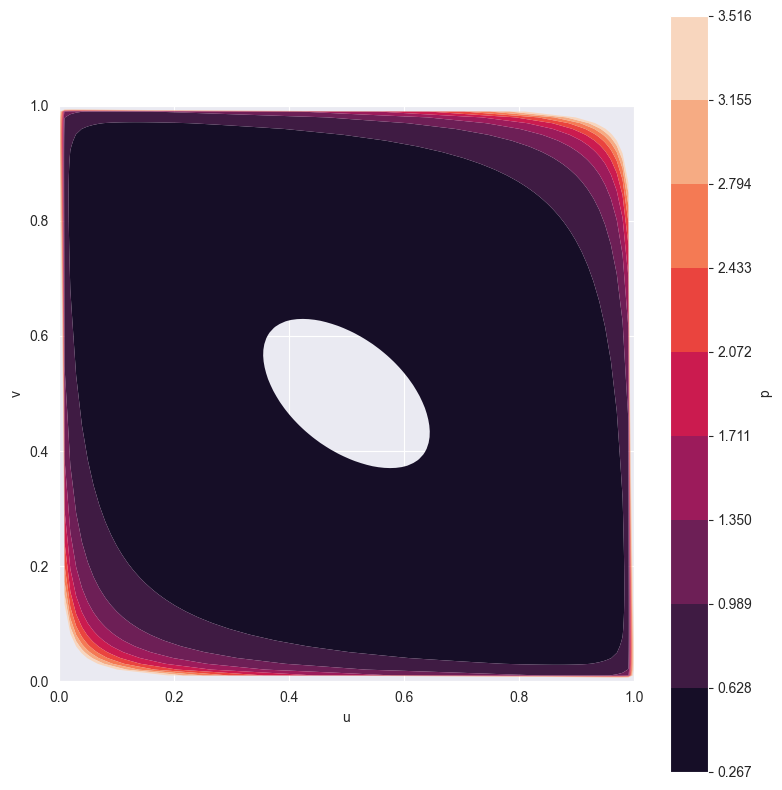

In [24]:
copula = GaussianCopula([[5,4.5],[4.5,7]], k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

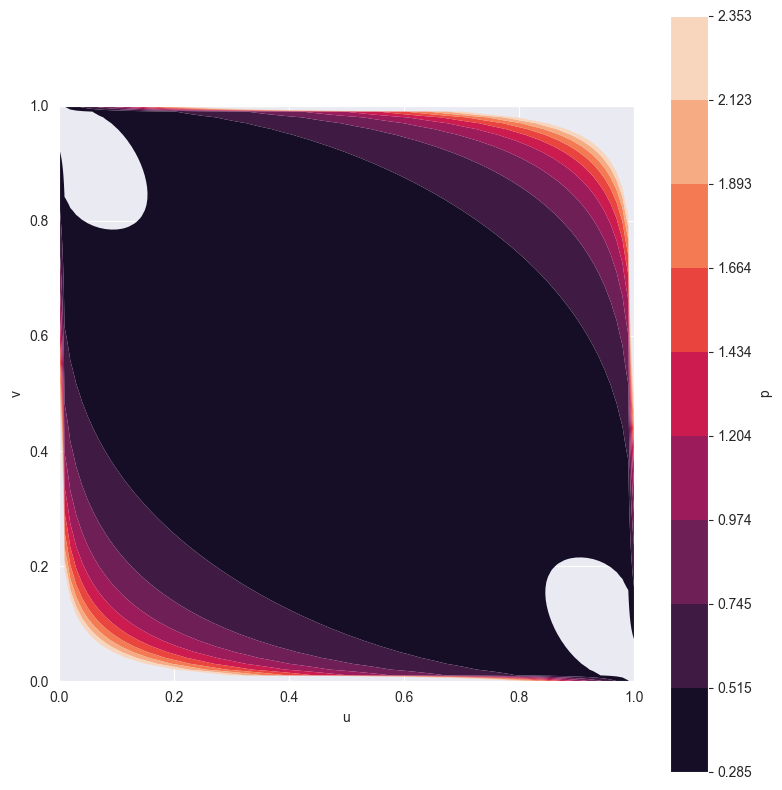

In [26]:
copula = GaussianCopula([[5,5],[5,7]], k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

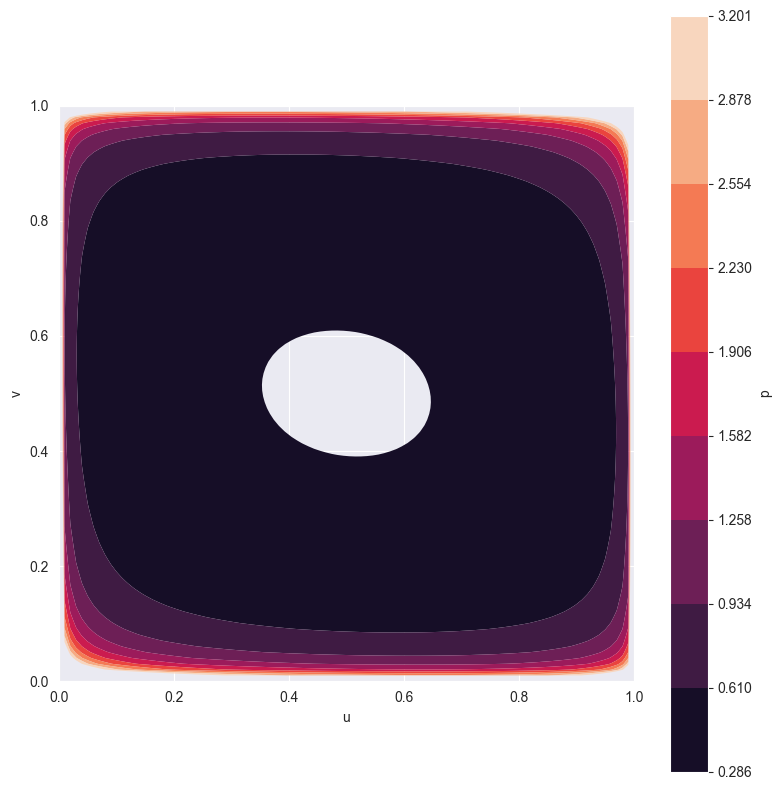

In [25]:
copula = GaussianCopula([[2,1],[1,7]], k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

# Student T copulae

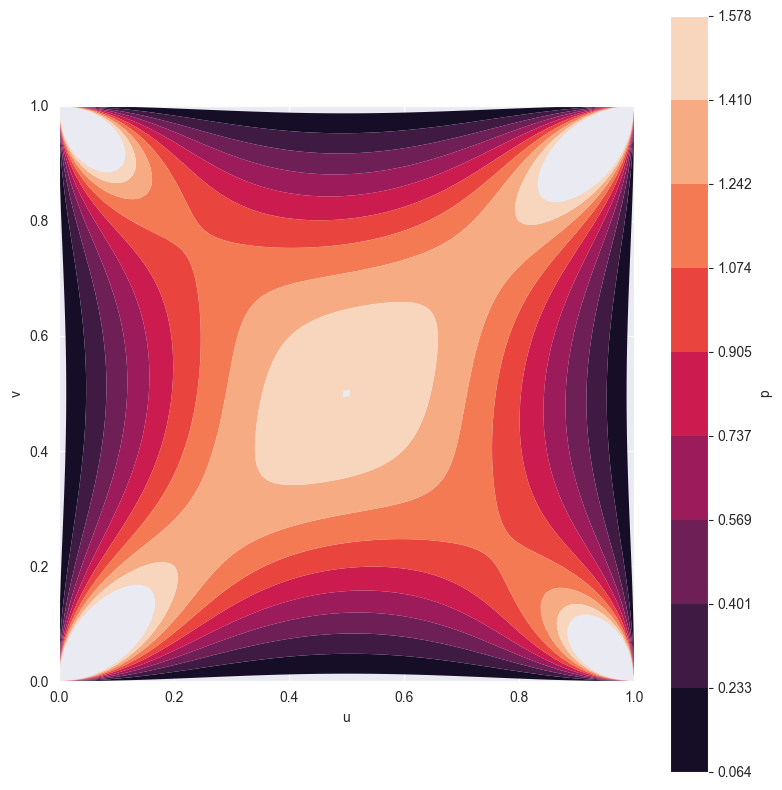

In [30]:
copula = StudentTCopula(0.1, df=1, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

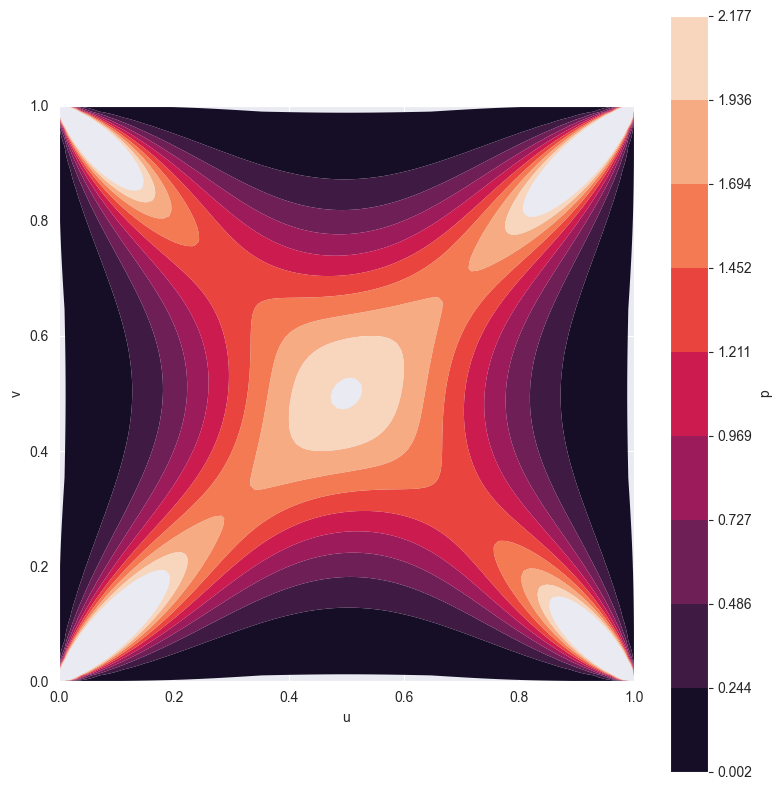

In [39]:
copula = StudentTCopula(0.1, df=0.5, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

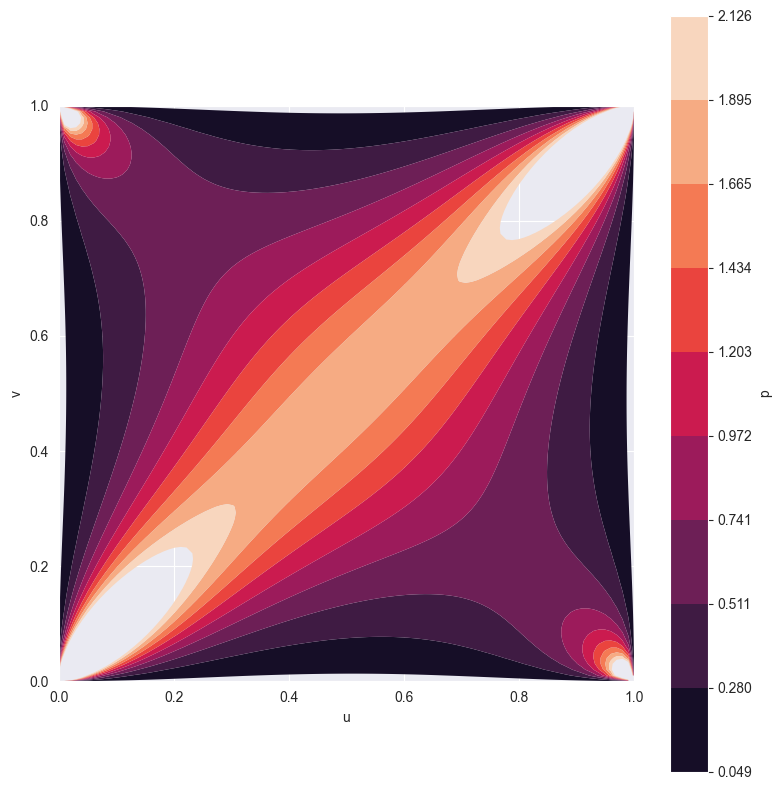

In [40]:
copula = StudentTCopula(0.5, df=1, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

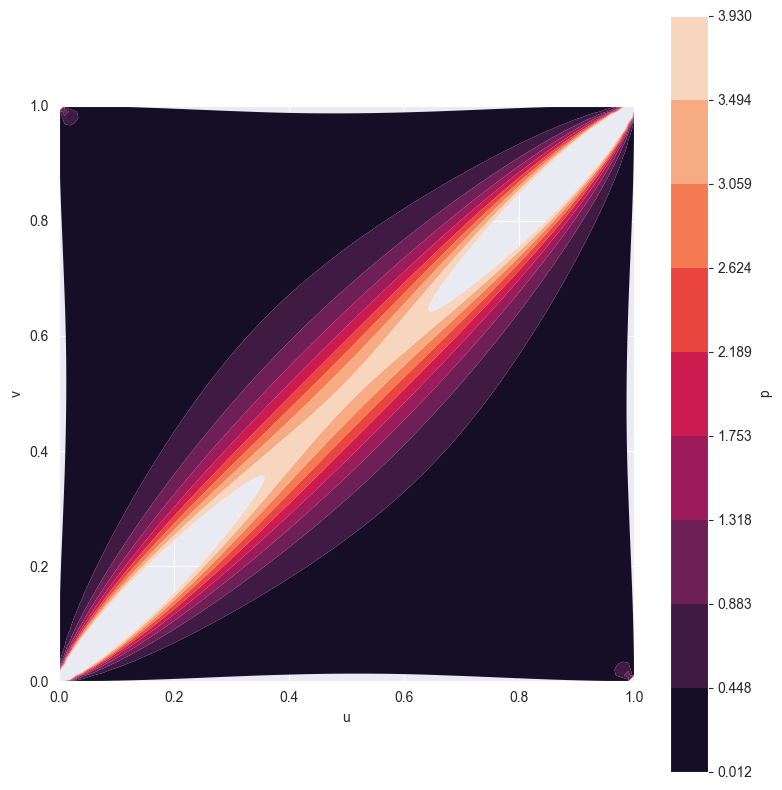

In [41]:
copula = StudentTCopula(0.9, df=1, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

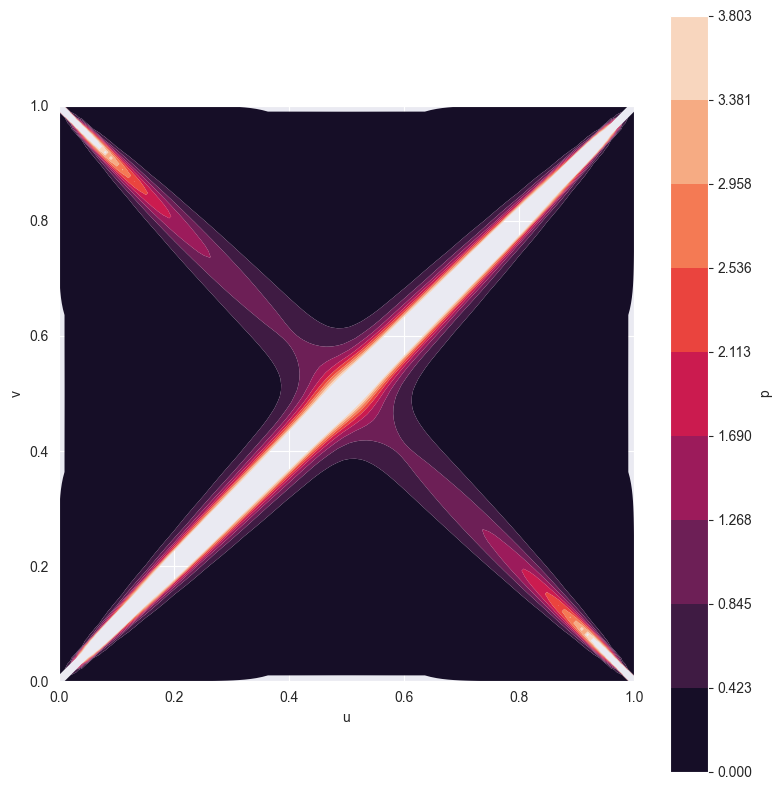

In [44]:
copula = StudentTCopula(0.9, df=0.1, k_dim=2)
_ = copula.plot_pdf()  # returns a matplotlib figure

# Plot student T copulas with slider

In [100]:
@interact(rho=(-1.0,1.0,0.05), log_df=(-5,7,0.1))
def plot_student_copula_from_correlation(rho=0.5, log_df=0):
    if rho==0:
        print("constant pdf")
    elif rho==1 or rho==-1:
        print("degenerate pdf")
    else:
        copula = StudentTCopula(rho, df=np.exp(log_df), k_dim=2)
        _ = copula.plot_pdf()  # returns a matplotlib figure

interactive(children=(FloatSlider(value=0.5, description='rho', max=1.0, min=-1.0, step=0.05), FloatSlider(val…

In [75]:
copula.pdf([[0.5,0.3], [0.2,0.3]])

array([1.27658703, 2.28171167])

In [76]:
copula.corr

array([[1. , 0.9],
       [0.9, 1. ]])

# Make sliders for varying the covariance matrix of Gaussian copula

Covariance matrix of bivariate normal:
$$
\boldsymbol\Sigma = \begin{pmatrix} \sigma_X^2 & \rho \sigma_X \sigma_Y \\
                             \rho \sigma_X \sigma_Y  & \sigma_Y^2 \end{pmatrix}
$$

Line of major axis of ellipse:
$$
y(x) = \rho\frac{\sigma_Y}{\sigma_X} (x - \mu _X) + \mu_Y
$$

In [96]:
@interact(rho=(-1.0,1.0,0.02), log_sd_ratio=(-4,4,0.1), log_sd_product=(-4,4,0.1))
def plot_gaussian_copula_from_corr_and_ratio(rho, log_sd_ratio, log_sd_product):
    if rho==0:
        print("constant pdf")
    elif rho==1 or rho==-1:
        print("degenerate pdf")
    else:
        sd_ratio, sd_product = np.exp([log_sd_ratio, log_sd_product])
        covariance_matrix = sd_product * np.array([[1/sd_ratio, rho], [rho, sd_ratio]])
        copula = GaussianCopula(covariance_matrix, k_dim=2)
        _ = copula.plot_pdf()  # returns a matplotlib figure

interactive(children=(FloatSlider(value=0.0, description='rho', max=1.0, min=-1.0, step=0.02), FloatSlider(val…

In [92]:
np.exp(3)

20.085536923187668

In [108]:
@interact(rho=(-1,1,0.02), log_sd_ratio=(-4,4,0.1), log_slope=(-4,4,0.1))
def plot_gaussian_copula_from_slope_ratio_scale(rho, log_sd_ratio, log_slope):
    if rho==0:
        print("constant pdf")
    elif rho==1 or rho==-1:
        print("degenerate pdf")
    else:
        sd_ratio, slope = np.exp([log_sd_ratio, log_slope])
        sd_product = slope / np.abs(rho)
        covariance_matrix = sd_product * np.array([[1/sd_ratio, rho], [rho, sd_ratio]])
        copula = GaussianCopula(covariance_matrix, k_dim=2)
        _ = copula.plot_pdf()  # returns a matplotlib figure

interactive(children=(FloatSlider(value=0.0, description='rho', max=1.0, min=-1.0, step=0.02), FloatSlider(val…